**Chilled Water Skid: Vapor Compression Chiller (R134a)**

In this tutorial we model a water chiller, a vapor compression refrigeration cycle that cools chilled water for air conditioning or process cooling, and validate it against an equivalent DWSIM model. It is the base model of the digital twin used in the case study notebooks `01`–`04`.

### The cycle:

Refrigerant R134a circulates in a closed loop: **compressor** → **condenser** (heat rejected to cooling water) → **expansion valve** → **evaporator** (heat taken from the chilled water) → back to the compressor.

| | Design |
|---|---|
| Refrigerant flow | 0.1375 kg/s R134a, compressor isentropic efficiency 75 % |
| Evaporator | U = 800 W/m²K, A = 5.249 m², counter-current; chilled water 1 kg/s at 12 °C |
| Condenser | U = 1000 W/m²K (clean), A = 1.97 m², counter-current; cooling water 1.22 kg/s at 30 °C |
| Controls | 5 K superheat at the evaporator outlet (expansion valve), 3 K subcooling at the condenser outlet |

$$COP = \frac{Q_{evaporator}}{W_{compressor}}$$

---

> **A closed loop with floating pressures**
>
> In DWSIM the compressor and valve outlet pressures are specified. `chiller.py` instead lets the condensing and evaporating pressures **float**: they are whatever the heat exchangers can deliver for the specified subcooling and superheat, as in a real chiller. This is what makes the model useful as a digital twin, because fouling or a warmer cooling water then changes the operating pressures, compressor power and COP. The refrigerant loop is closed directly in the equation-oriented model, without the recycle (tear) block a sequential simulator needs.

> **Fouling**
>
> Fouling adds a thermal resistance $R_f$ to each exchanger: $U = 1/(1/U_{clean} + R_f)$.

> **Properties**
>
> R134a uses the IDAES Helmholtz equation of state (the same reference equation as CoolProp, which DWSIM uses), and water the IAPWS-95 steam tables. The heat exchangers use a smooth LMTD formulation: at the design point both ends of the evaporator have nearly the same temperature difference (5 K), where the exact LMTD formula becomes 0/0.

In [1]:
import idaes

print("IDAES version: ", idaes.__version__)

IDAES version:  2.13.0


## Setting up and solving the chiller

In [2]:
from chiller import setup_chiller_model, chiller_results

# Build, initialize and solve the chiller at its design point
model, results = setup_chiller_model()
print(results.solver.termination_condition)
cop_clean = chiller_results(model)["COP"]
print("Design COP: {0:.3f}".format(cop_clean))

The DOF is 0
optimal
Design COP: 4.563


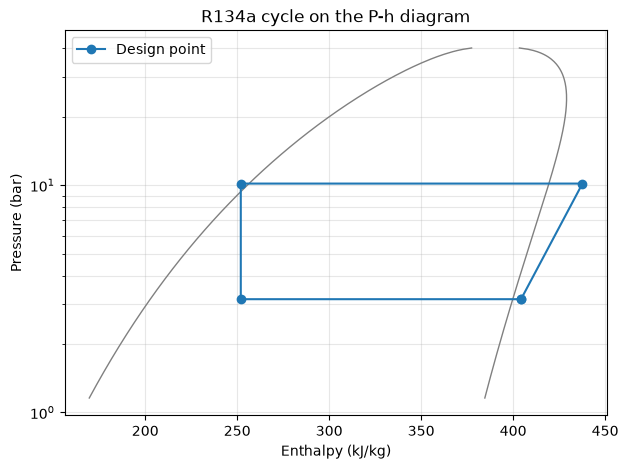

In [3]:
from chiller import cycle_points, plot_ph
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))
plot_ph(ax, {"Design point": cycle_points(model)})
plt.show()

In [4]:
# Visualize (if needed)
model.fs.visualize("Chiller Model")

'idaes.co re.util.diagnostics_tools.diagnostics_toolbox.DiagnosticsToolbox'.
Please update your import.  (deprecated in 2.12.0) (called from <frozen
importlib._bootstrap>:488)
'idaes.core.util.diagnostics_tools.diagnostics_toolbox.CONFIG'. Please update
your import.  (deprecated in 2.12.0) (called from <frozen
importlib._bootstrap>:488)
2026-11-10 21:28:40 [INFO] idaes.idaes_ui.fv.fsvis: Started visualization server
2026-11-10 21:28:40 [INFO] idaes.idaes_ui.fv.fsvis: Saving flowsheet to default file 'Chiller Model.json' in current directory (c:\Users\VirajDesai\Downloads\Personal\Github\IDAES-PSE-Examples\Refrigeration Chilled Water Skid)
2026-11-10 21:28:41 [WARNING] idaes.idaes_ui.fv.fsvis: Flowsheet name changed: old='Chiller Model' new='Chiller-Model'
Flowsheet name changed to 'Chiller-Model'
2026-11-10 21:28:41 [INFO] idaes.idaes_ui.fv.fsvis: Flowsheet visualization at: http://localhost:58129/app?id=Chiller-Model


VisualizeResult(store=<idaes_ui.fv.persist.FileDataStore object at 0x0000015DC4B955B0>, port=58129, server=<idaes_ui.fv.model_server.FlowsheetServer object at 0x0000015DC4C3EBD0>, save_diagram=<bound method SaveDiagramScreenshot.save_diagram_screenshot of <idaes_ui.fv.save_diagram_screenshot.SaveDiagramScreenshot object at 0x0000015DC4C2FB00>>)

## Validation against DWSIM

The DWSIM results are read directly from the solved `.dwxmz` file. IDAES calculates the pressures from the superheat and subcooling, and they land on the pressures specified in DWSIM.

In [5]:
from chiller import read_dwsim_results, compare_with_dwsim

dwsim = read_dwsim_results("DWSim Refrigeraion Chilled Water Skid.dwxmz")
compare_with_dwsim(model, dwsim)

,IDAES,DWSIM,Difference,Error (%)
Evaporator pressure (bar),3.147884,3.149981,-0.002097,-0.066573
Evaporating temperature (C),2.015072,2.033764,-0.018692,-0.919099
Condenser pressure (bar),10.164083,10.170000,-0.005917,-0.058180
Condensing temperature (C),39.993225,40.014925,-0.021701,-0.054231
Suction temperature (C),7.015072,7.022194,-0.007122,-0.101423
Discharge temperature (C),56.642805,56.627483,0.015322,0.027057
Condenser outlet temperature (C),36.993225,36.995459,-0.002234,-0.006040
Valve outlet vapor fraction,0.249765,0.249671,0.000094,0.037758
Chilled water supply (C),7.007601,7.008039,-0.000438,-0.006253
Cooling water outlet (C),35.008771,35.007998,0.000773,0.002209
